In [2]:
def load_csv(filename):
    data = []

    with open(filename, "r", encoding='utf-8') as file:
        header = file.readline().strip().split(",")[1:]
        for line in file:
            values = line.strip().split(",")[1:]

            year = int(values[0])
            region = values[1]
            annual_rent_sqm = int(values[2])
            income = float(values[3])
            # data.append(values)
            data.append([year, region, annual_rent_sqm, income])
    return header, data

header, values = load_csv("datasets/lab3/inc_vs_rent.csv")
print(header, values)

['year', 'region', 'Annual rent sqm', 'Avg yearly inc KSEK'] [[2020, '01 Stockholm county', 1341, 350.30370370370366], [2020, '03 Uppsala county', 1303, 306.91604938271604], [2020, '04 Södermanland county', 1129, 283.75679012345677], [2020, '05 Östergötland county', 1144, 289.5], [2020, '06 Jönköping county', 1044, 287.47037037037035], [2020, '07 Kronoberg county', 1040, 282.4246913580247], [2020, '08 Kalmar county', 1008, 278.19629629629634], [2020, '09 Gotland county', 1120, 270.56296296296296], [2020, '10 Blekinge county', 1096, 282.94444444444446], [2020, '12 Skåne county', 1212, 294.2456790123457], [2020, '13 Halland county', 1155, 304.25802469135806], [2020, '14 Västra Götaland county', 1145, 300.6320987654321], [2020, '17 Värmland county', 1040, 282.5074074074074], [2020, '18 Örebro county', 1109, 284.28765432098766], [2020, '19 Västmanland county', 1102, 292.141975308642], [2020, '20 Dalarna county', 1031, 283.0234567901235], [2020, '21 Gävleborg county', 1031, 279.988888888888

What information can you get by just looking at the table?

In [9]:
print(header)

['year', 'region', 'Annual rent sqm', 'Avg yearly inc KSEK']


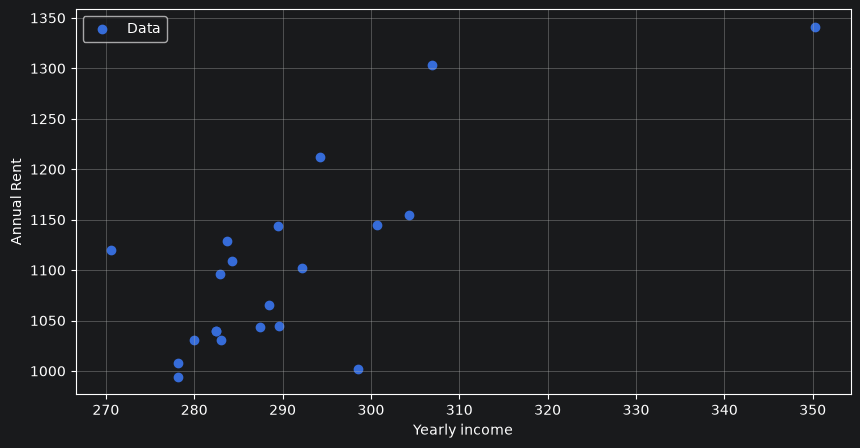

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.DataFrame(values, columns=header)
y = df["Annual rent sqm"]
x = df["Avg yearly inc KSEK"]

plt.figure(figsize=(10, 5))
plt.scatter(x, y, label="Data")
plt.xlabel("Yearly income")
plt.ylabel("Annual Rent")
plt.grid()
plt.legend()
plt.show()


Implement the k-means algorithm from scratch using the object-oriented principles you learned in the previous week.
We learned that for the K-means implementation, we need:
- Attributes: Hyperparameter k, Max Iterations, Reference to Dataset, Current inertia, Silhouette score, Current centroids, Current assignment
- Methods: Count inertia, Count silhouette, Initialize centroids, Recalculate centroids, Assign points to closest centroid, Distance, Run

In [4]:
# Pick a value for the number of clusters.
# Initialize the centroids as a random points among your sample.
# Find which point belongs to which cluster by finding the closer centroid to every point (Euclidean distance).
# Calculate the mean point among each cluster to obtain the new centroids.
# Repeat this process for N (around 10) number of iterations until the mean of the new cluster does not change from the previous iteration.
# Create once again a cluster plot with colors assigned for each cluster.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
from sklearn.preprocessing import StandardScaler

class Clustering:
    _default_k = 3

    def __init__(self, k):
        if k < 1:
            k = Clustering._default_k
        self._n_clusters = k
        self._x = None          # Data, set when we call fit()
        self._labels = None
        self._fitted = False

    def getK(self):
        return self._n_clusters

    def setK(self, k):
        if k < 1:
            k = Clustering._default_k
        self._n_clusters = k
        self._fitted = False            # Old results no longer match the new k

    def whatAmI(self):
        print("I am a Clustering of ", self._n_clusters, "clusters")

    def fit(self, x):
        raise NotImplementedError("Different subclasses algorithms must implement this")

    def _check_fitted(self):
        if not self._fitted:
            raise RuntimeError("You must call fit before calling this method")

    def getLabels(self):
        self._check_fitted()
        return self._labels


In [50]:
class KMeansAlg(Clustering):
    def __init__(self, k, n_init=10, random_state=42, standardize=True):
        super().__init__(k)
        self._n_init = n_init           # 10 Random initializations (keeps the best)
        self._random_state = random_state
        self._standardize_data = standardize
        self._mean = None
        self._std = None
        self._model = None              # The scikit-learn KMeans, created in fit()
        self._centroids = None          # For personal implementation
        self._inertia = None            # For personal impl

    def whatAmI(self):
        print("I am a KMeans Clustering of ", self._n_clusters, "clusters")

    def getCentroids(self):
        self._check_fitted()
        return self._centroids

    def getInertia(self):
        self._check_fitted()
        return self._inertia


    # ~~~~ Standardize methods for the data (Z-score)
    def _fitScaler(self, x):                # Learn means and standard deviations of training data
        self._mean = np.mean(x, axis=0)     # axis=0: Operates downward along the rows (and column by column) | axis=1: Operates horizontally across the columns (row by row)
        self._std = np.std(x, axis=0)
        self._std[self._std == 0] = 1       # Avoiding division by 0
        return self

    def _scale(self, x):
        if not self._standardize_data:
            return x
        return (x - self._mean) / self._std

    def _unscale(self, x_scaled):
        if not self._standardize_data:
            return x_scaled
        return x_scaled * self._std + self._mean
    # ~~~~~~


    def fit(self, x):
        self._x = self._fitScaler(x)._scale(x)
        self._model = KMeans(n_clusters=self._n_clusters, n_init=self._n_init, random_state=self._random_state)
        self._labels = self._model.fit_predict(self._x)
        self._fitted = True
        self._centroids = self._model.cluster_centers_
        self._inertia = self._model.inertia_
        return self                     # Allows chaining: KMeansClusterer(5).fit(X)

    # ~~~~~~~~~~~KMEANS PERSONAL IMPLEMENTATION

    # ---- Helper 1
    def _assignClusters(self, x, centroids):
        lenx = x.shape[0]                    # shape is (rows, columns), so shape[0] is the number of points.
        lencentroids = centroids.shape[0]            # number of centroids
        D = np.zeros((lenx, lencentroids))              # D has one row per point and one column per centroid.

        for i in range(lenx):                # outer loop: every instance
            for j in range(lencentroids):            # inner loop: every centroid
                D[i, j] = np.linalg.norm(x[i] - centroids[j]) # Euclidian distance (norm takes the square root)

        labels = np.argmin(D, axis=1)  # axis=1 looks across the columns of each row

        return labels, D

    # ---- Helper 2
    def _updateCentroids(self, x, labels, old_centroids):
        lencentroids = old_centroids.shape[0]
        lenfeatures = old_centroids.shape[1]
        new_centroids = np.zeros((lencentroids, lenfeatures))

        for j in range(lencentroids):
            cluster_points = x[labels == j]
            if len(cluster_points) > 0:
                new_centroids[j] = np.mean(cluster_points, axis=0)
            else:
                new_centroids[j] = old_centroids[j]

        return new_centroids

    # ---- ONE run of K-Means
    def KMeansPersonal(self, x, rng, max_iter=300):
        centroids = rng.choice(self._x, self._n_clusters, replace=False) # replace=False means no row can be picked twice.
        for _ in range(max_iter):
            labels, D = self._assignClusters(x, centroids)
            new_centroids = self._updateCentroids(x, labels, centroids)
            if np.allclose(new_centroids, centroids): # similar to == (up to a tiny tolerance)
                break
            else:
                centroids = new_centroids

        # Final assignment so labels and D match the centroids we return
        labels, D = self._assignClusters(x, centroids)

        # Inertia: sum of SQUARED distances from each instance to ITS OWN centroid
        inertia = 0
        lenx = x.shape[0]
        for i in range(lenx):                # outer loop: every instance
            inertia = inertia + D[i, labels[i]] ** 2
        return centroids, labels, inertia

    # ---- Repeat KMeansPersonal n_init (10) times and keeps BEST
    def fitPersonal(self, x):
        self._model = None      # Forget sklearn model if used
        self._x = self._fitScaler(x)._scale(x)
        rng = np.random.default_rng(self._random_state)   # 1 generator for ALL runs
        best_inertia = np.inf                              # any real inertia will be lower
        for _ in range(self._n_init):
            centroids, labels, inertia = self.KMeansPersonal(self._x, rng)
            if inertia < best_inertia:
                best_inertia = inertia
                self._centroids = centroids
                self._labels = labels
                self._inertia = inertia
        self._fitted = True
        return self

# Hyper - parameter optimization
    # ~~~~~ Silhouette implementation

    def avgIntraCluster(self, i, D):
        mask = (self._labels == self._labels[i])
        mask[i] = False
        if np.sum(mask) == 0:
            return 0
        return np.mean(D[i, mask])

    def avgInterCluster(self, i, D):
        means = []
        for j in range(self._n_clusters):
            if j == self._labels[i]:    # Skip own cluster
                continue
            mask = (self._labels == j)
            if np.sum(mask) == 0:       # Empty cluster: nothing to average
                continue
            means.append(np.mean(D[i, mask]))
        return min(means)

    def personalSilhouette(self):
        self._check_fitted()
        if len(np.unique(self._labels)) < 2:
            return 0.0
        _, D = self._assignClusters(self._x, self._x)   # D[i, j] is now the distance between point i and point j
        m = self._x.shape[0]
        s = np.zeros(m)
        for i in range(m):
            if np.sum(self._labels == self._labels[i]) == 1: # If sum is 1, the point is alone in its cluster
                s[i] = 0
                continue
            a = self.avgIntraCluster(i, D)
            b = self.avgInterCluster(i, D)
            denom = max(a, b)
            s[i] = (b - a) / denom if denom != 0 else 0
        return np.mean(s)                               # average S(i) over all points

    # ~~~~Sklearn:
    def getSilhouette(self):
        self._check_fitted()
        return silhouette_score(self._x, self._labels)
    # ~~~~

    def predict(self, x_new):
        self._check_fitted()
        x_new_scaled = self._scale(x_new)
        labels, D = self._assignClusters(x_new_scaled, self._centroids)
        return labels, D
    '''
    def predict(self, x_new):
        self._check_fitted()
        x_new_scaled = self._scale(x_new)
        return self._model.predict(x_new_scaled)
    '''

    def getOriginalCentroids(self):
        self._check_fitted()
        return self._unscale(self._centroids)

In [60]:
# ---- 1. Comparing sklearn KMeans vs our KMeans
X_raw = df[["Avg yearly inc KSEK", "Annual rent sqm"]].values
k = 3
kmeans_sk = KMeansAlg(k).fit(X_raw)
kmeans_mine = KMeansAlg(k).fitPersonal(X_raw)

print("Inertia    sklearn:", kmeans_sk.getInertia(), "| mine:", kmeans_mine.getInertia())
print("Silhouette sklearn:", kmeans_sk.getSilhouette(), "| mine:", kmeans_mine.personalSilhouette())


Inertia    sklearn: 8.727933252160494 | mine: 10.052171038458614
Silhouette sklearn: 0.4723417738383282 | mine: 0.38515464002647043


In [58]:
kmeans_non_stand = KMeansAlg(3, standardize=False).fitPersonal(X_raw)
print("Silhouette coefficient with data not standardized: ", kmeans_non_stand.getSilhouette(),"| standardized: ", kmeans_mine.getSilhouette())

Silhouette coefficient with data not standardized:  0.6464284636214808 | standardized:  0.3851546400264703


In [7]:
# ---- 2. Which counties ended up together? ----
df["cluster_sk"] = kmeans_sk.getLabels()
df["cluster_mine"] = kmeans_mine.getLabels()
print(df[["region", "cluster_sk", "cluster_mine"]].sort_values("cluster_mine").to_string(index=False))

                   region  cluster_sk  cluster_mine
      01 Stockholm county           1             0
        03 Uppsala county           2             0
   04 Södermanland county           0             1
   05 Östergötland county           2             1
         18 Örebro county           0             1
14 Västra Götaland county           2             1
        13 Halland county           2             1
          12 Skåne county           2             1
    19 Västmanland county           0             1
         08 Kalmar county           0             2
      07 Kronoberg county           0             2
      06 Jönköping county           0             2
        09 Gotland county           0             2
       10 Blekinge county           0             2
       17 Värmland county           0             2
        20 Dalarna county           0             2
      21 Gävleborg county           0             2
 22 Västernorrland county           0             2
       23 Jä

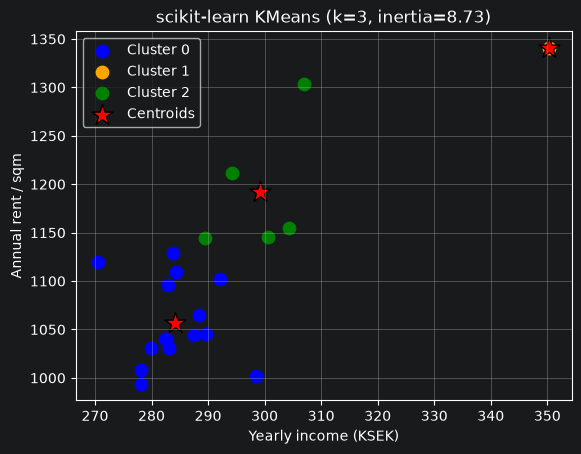

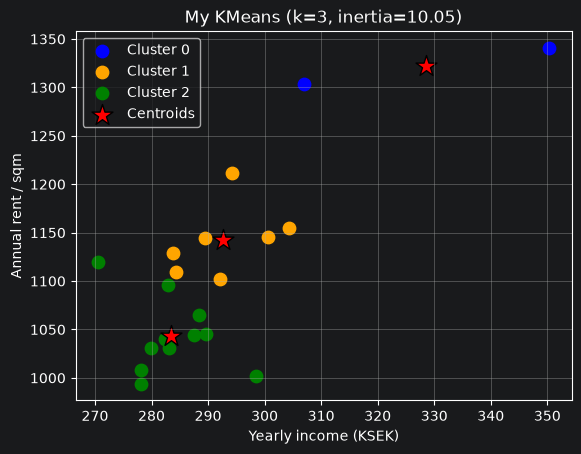

In [32]:
# ---- 3. Cluster plot: one color and one marker per cluster (original units) ----
def plotClusters(x_raw, model, title):
    labels = model.getLabels()
    cents = model.getOriginalCentroids() # We unscale centroids

    income = x_raw[:, 0]          # column 0 of every row = yearly income
    rent = x_raw[:, 1]            # column 1 of every row = annual rent
    cent_income = cents[:, 0]
    cent_rent = cents[:, 1]

    colors = ["blue", "orange", "green", "purple", "brown", "pink", "gray", "olive", "cyan", "black"]

    for c in range(model.getK()):                         # one scatter call per cluster
        plt.scatter(income[labels == c], rent[labels == c],    # only the points of cluster c
                   color=colors[c], s=80, label=f"Cluster {c}")

    plt.scatter(cent_income, cent_rent, marker="*", s=250, color="red",
               edgecolors="black", label="Centroids")
    plt.title(f"{title} (k={model.getK()}, inertia={model.getInertia():.2f})")
    plt.xlabel("Yearly income (KSEK)")
    plt.ylabel("Annual rent / sqm")
    plt.grid()
    plt.legend()

plotClusters(X_raw, kmeans_sk, "scikit-learn KMeans")
plt.show()
plotClusters(X_raw, kmeans_mine, "My KMeans")
plt.show()

In [33]:
def silhouetteGridSearch(x, k_values):
    scores = []
    inertias = []
    for k in k_values:
        model = KMeansAlg(k).fitPersonal(x)
        inertias.append(model.getInertia())
        if k == 1:  # With 1 cluster there is no "other cluster", so b(i) is undefined -> score 0 by convention
            scores.append(0.0)
        else:
            scores.append(model.personalSilhouette())
    return scores, inertias

Scores: [0.    0.661 0.385 0.394 0.363 0.32  0.309 0.265 0.34  0.415]
Inertias:  [42.   16.8  10.05  7.5   4.09  3.58  2.55  2.02  1.31  1.12]
Best k: 2


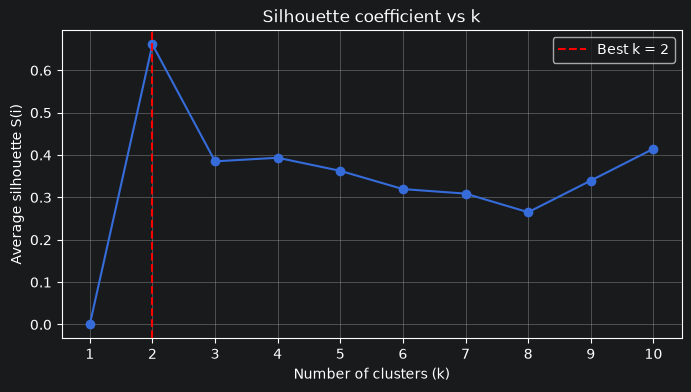

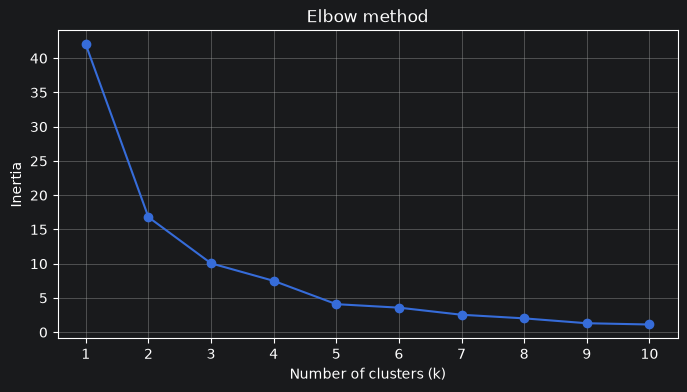

In [55]:
X_raw = df[["Avg yearly inc KSEK", "Annual rent sqm"]].values

# Graph the cluster’s silhouette coefficient for each value in the grid to determine the optimal number of clusters:
k_values = list(range(1, 11))
scores, inertias = silhouetteGridSearch(X_raw, k_values)
best_k = k_values[np.argmax(scores)]          # argmax gives a position; k starts at 1, so we index k_values
print("Scores:", np.round(scores, 3))
print("Inertias: ", np.round(inertias, 2))
print("Best k:", best_k)

# Silhouette plot:
plt.figure(figsize=(8, 4))
plt.plot(k_values, scores, "o-")
plt.axvline(best_k, color="red", linestyle="--", label=f"Best k = {best_k}")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average silhouette S(i)")
plt.title("Silhouette coefficient vs k")
plt.xticks(k_values)
plt.grid()
plt.legend()
plt.show()

# Elbow (Inertias) plot:
plt.figure(figsize=(8, 4))
plt.plot(k_values, inertias, "o-")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.xticks(k_values)
plt.grid()
plt.show()

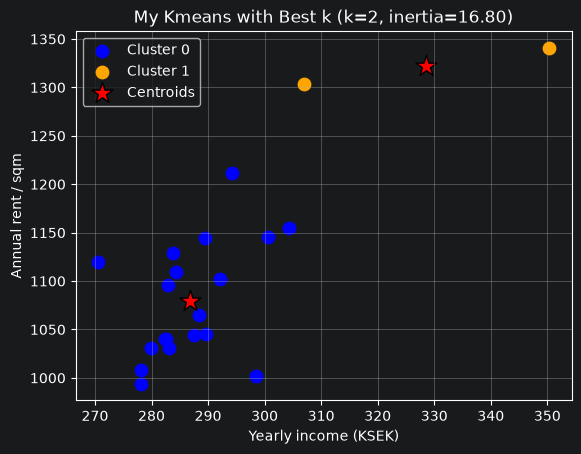

In [35]:
best = KMeansAlg(best_k).fitPersonal(X_raw)
plotClusters(X_raw, best, "My Kmeans with Best k")
plt.show()


Predicted clusters: [0 1 0]


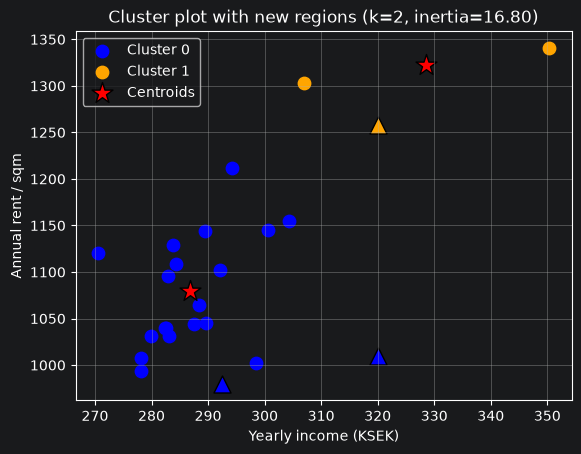

In [51]:
# New regions in the MODEL's column order: [income, rent]
new_points = np.array([[320.12, 1010],
                       [320,    1258],
                       [292.4,  980]])

model = KMeansAlg(best_k).fitPersonal(X_raw)
new_labels, _ = model.predict(new_points)
print("Predicted clusters:", new_labels)

plotClusters(X_raw, model, "Cluster plot with new regions")

colors = ["blue", "orange", "green", "purple", "brown", "pink", "gray", "olive", "cyan", "black"]

for n, (p, lab) in enumerate(zip(new_points, new_labels)):
    plt.scatter(p[0], p[1], marker="^", s=150, color=colors[lab],
               edgecolor="black")

plt.ylabel("Annual rent / sqm")
plt.show()

Based on the cluster graph do you think your model successfully predicted the cluster for these values?
Yes, the new values are in the cluster which centroids are closer to them. But what if K=3?

[[3.47408376 2.24980396 2.31992372]
 [0.88649778 2.1303247  3.28834813]
 [4.39210584 1.78589831 0.88983941]]
Predicted clusters: [1 0 2]


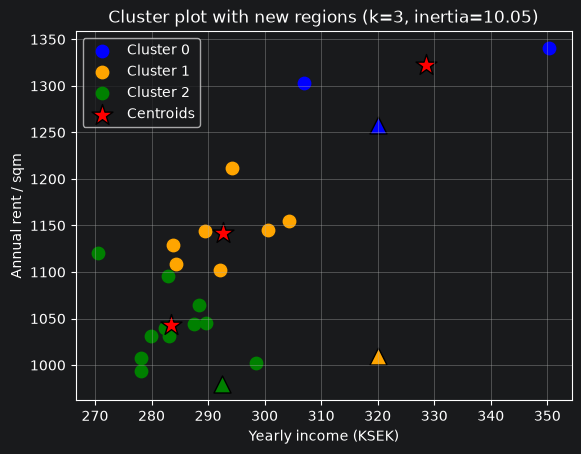

In [53]:
k=3
model = KMeansAlg(k).fitPersonal(X_raw)
new_labels, D = model.predict(new_points)
print(D)
print("Predicted clusters:", new_labels)

plotClusters(X_raw, model, "Cluster plot with new regions")

colors = ["blue", "orange", "green", "purple", "brown", "pink", "gray", "olive", "cyan", "black"]

for n, (p, lab) in enumerate(zip(new_points, new_labels)):
    plt.scatter(p[0], p[1], marker="^", s=150, color=colors[lab],
               edgecolor="black")

plt.ylabel("Annual rent / sqm")
plt.show()

The new point in the bottom right can seem closer to cluster 2, however the distances show us that is closer to the centroid of cluster 1, with a distance of aprox 2.25 units against the centroid of cluster 2 with a distance of 2.32 (Very similar with each other).